In [1]:

from google.colab import files

uploaded = files.upload()

Saving chatgpt_reviews.csv to chatgpt_reviews.csv


In [2]:

import pandas as pd

df = pd.read_csv('chatgpt_reviews.csv')

print("Dataset shape:", df.shape)
display(df.head())


Dataset shape: (196727, 4)


,Review Id,Review,Ratings,Review Date
0,6fb93778-651a-4ad1-b5ed-67dd0bd35aac,good,5,2024-08-23 19:30:05
1,81caeefd-3a28-4601-a898-72897ac906f5,good,5,2024-08-23 19:28:18
2,452af49e-1d8b-4b68-b1ac-a94c64cb1dd5,nice app,5,2024-08-23 19:22:59
3,372a4096-ee6a-4b94-b046-cef0b646c965,"nice, ig",5,2024-08-23 19:20:50
4,b0d66a4b-9bde-4b7c-8b11-66ed6ccdd7da,"this is a great app, the bot is so accurate to...",5,2024-08-23 19:20:39


In [3]:

# Check the data types and non-null counts
print("DATASET INFORMATION")
df.info()

# Check missing values in each column
print("\nMISSING VALUES")
print(df.isnull().sum())

# Check duplicate rows
print("\nDUPLICATE ROWS")
print(df.duplicated().sum())

# Check duplicate review IDs
print("\nDUPLICATE REVIEW IDs")
print(df["Review Id"].duplicated().sum())

# Check the rating distribution
print("\nRATING DISTRIBUTION")
print(df["Ratings"].value_counts().sort_index())

# Check the date column format
print("\nDATE COLUMN TYPE")
print(df["Review Date"].dtype)


DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 196727 entries, 0 to 196726
Data columns (total 4 columns):
 #   Column       Non-Null Count   Dtype 
---  ------       --------------   ----- 
 0   Review Id    196727 non-null  object
 1   Review       196721 non-null  object
 2   Ratings      196727 non-null  int64 
 3   Review Date  196727 non-null  object
dtypes: int64(1), object(3)
memory usage: 6.0+ MB

MISSING VALUES
Review Id      0
Review         6
Ratings        0
Review Date    0
dtype: int64

DUPLICATE ROWS
2511

DUPLICATE REVIEW IDs
3573

RATING DISTRIBUTION
Ratings
1     12083
2      3375
3      8157
4     22897
5    150215
Name: count, dtype: int64

DATE COLUMN TYPE
object


In [4]:

# Examine records with duplicate review IDs
duplicate_id_rows = df[
    df["Review Id"].duplicated(keep=False)
].sort_values("Review Id")

print("Total records with repeated IDs:", len(duplicate_id_rows))

print("\nFirst 15 records with repeated IDs:")
display(duplicate_id_rows.head(15))

# Check whether repeated IDs have different review texts
reviews_per_id = df.groupby("Review Id")["Review"].nunique(
    dropna=False
)

print(
    "\nIDs associated with multiple distinct review values:",
    (reviews_per_id > 1).sum()
)

# Check valid rating range
print("\nUnique ratings:")
print(sorted(df["Ratings"].dropna().unique()))


Total records with repeated IDs: 5419

First 15 records with repeated IDs:


,Review Id,Review,Ratings,Review Date
78968,0009b10b-59f3-4c66-a68d-d330ad280a55,သဘောတွေ့ပါတယ်ခက်ဗျာ,5,2024-05-17 10:26:45
79634,0009b10b-59f3-4c66-a68d-d330ad280a55,သဘောတွေ့ပါတယ်ခက်ဗျာ,5,2024-05-17 10:26:45
80290,0009b10b-59f3-4c66-a68d-d330ad280a55,သဘောတွေ့ပါတယ်ခက်ဗျာ,5,2024-05-17 10:26:45
79372,000ca1a5-ed93-4cf2-875e-6e8bb4941bf6,good,5,2024-05-17 03:54:56
80694,000ca1a5-ed93-4cf2-875e-6e8bb4941bf6,good,5,2024-05-17 03:54:56
80038,000ca1a5-ed93-4cf2-875e-6e8bb4941bf6,good,5,2024-05-17 03:54:56
2254,003818b9-6f10-4d69-bd8c-2fe4e6393961,very great app,5,2024-08-21 15:31:36
11354,003818b9-6f10-4d69-bd8c-2fe4e6393961,very great app,5,2024-08-11 16:08:15
16131,00527c7e-9ea8-4477-a611-b391c00defc1,I can't sign in using Microsoft account. It ju...,1,2024-08-06 03:06:58
65871,00527c7e-9ea8-4477-a611-b391c00defc1,I can't assign in using Microsoft account. It ...,2,2024-05-29 17:56:50



IDs associated with multiple distinct review values: 764

Unique ratings:
[np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)]


In [5]:

# Step 1: Preserve the original dataset
df_clean = df.copy()

# Step 2: Standardize column names
df_clean.columns = (
    df_clean.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

print("Updated columns:")
print(df_clean.columns.tolist())

# Step 3: Remove exact duplicate rows only
before = len(df_clean)

df_clean = df_clean.drop_duplicates()

removed = before - len(df_clean)

print("\nExact duplicate rows removed:", removed)
print("Rows remaining:", len(df_clean))

# Step 4: Convert review dates to datetime
df_clean["review_date"] = pd.to_datetime(
    df_clean["review_date"],
    errors="coerce"
)

print("\nInvalid dates:", df_clean["review_date"].isna().sum())

# Step 5: Remove records without review text
before_text_filter = len(df_clean)

df_text = df_clean.dropna(subset=["review"]).copy()

# Remove reviews containing only whitespace
df_text["review"] = df_text["review"].astype(str).str.strip()
df_text = df_text[df_text["review"] != ""]

print("\nRecords excluded for missing/empty reviews:",
      before_text_filter - len(df_text))

print("Final dataset for text analysis:", df_text.shape)

# Step 6: Verify the cleaned data
print("\nRemaining missing values:")
print(df_clean.isnull().sum())

print("\nCleaned sample:")
display(df_text.head())


Updated columns:
['review_id', 'review', 'ratings', 'review_date']

Exact duplicate rows removed: 2511
Rows remaining: 194216

Invalid dates: 0

Records excluded for missing/empty reviews: 6
Final dataset for text analysis: (194210, 4)

Remaining missing values:
review_id      0
review         6
ratings        0
review_date    0
dtype: int64

Cleaned sample:


,review_id,review,ratings,review_date
0,6fb93778-651a-4ad1-b5ed-67dd0bd35aac,good,5,2024-08-23 19:30:05
1,81caeefd-3a28-4601-a898-72897ac906f5,good,5,2024-08-23 19:28:18
2,452af49e-1d8b-4b68-b1ac-a94c64cb1dd5,nice app,5,2024-08-23 19:22:59
3,372a4096-ee6a-4b94-b046-cef0b646c965,"nice, ig",5,2024-08-23 19:20:50
4,b0d66a4b-9bde-4b7c-8b11-66ed6ccdd7da,"this is a great app, the bot is so accurate to...",5,2024-08-23 19:20:39


Rating counts:
ratings
1     11966
2      3346
3      8046
4     22603
5    148255
Name: count, dtype: int64


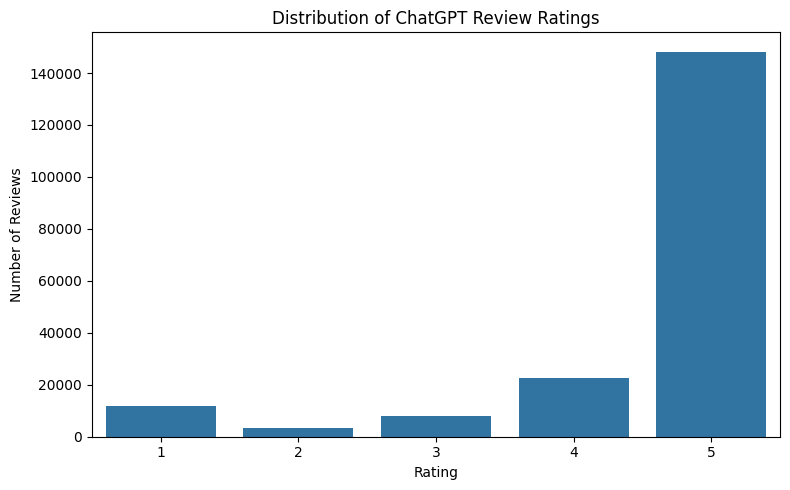

In [6]:

import matplotlib.pyplot as plt
import seaborn as sns

# Count reviews for each rating
rating_counts = df_clean["ratings"].value_counts().sort_index()

print("Rating counts:")
print(rating_counts)

# Create a bar chart
plt.figure(figsize=(8, 5))

sns.barplot(
    x=rating_counts.index,
    y=rating_counts.values
)

plt.title("Distribution of ChatGPT Review Ratings")
plt.xlabel("Rating")
plt.ylabel("Number of Reviews")
plt.xticks([0, 1, 2, 3, 4], [1, 2, 3, 4, 5])
plt.tight_layout()
plt.show()


In [7]:

rating_percentages = (
    df_clean["ratings"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

print("Rating percentages:")
print(rating_percentages.round(2))

print(
    "\nPercentage of 5-star ratings:",
    round(rating_percentages.loc[5], 2), "%"
)


Rating percentages:
ratings
1     6.16
2     1.72
3     4.14
4    11.64
5    76.34
Name: proportion, dtype: float64

Percentage of 5-star ratings: 76.34 %


Monthly review counts:
review_month
2023-07     8283
2023-08     6801
2023-09     7593
2023-10     5824
2023-11     8719
2023-12    10375
2024-01     9313
2024-02     8748
2024-03    15175
2024-04    23739
2024-05    25814
2024-06    18411
2024-07    25259
2024-08    20162
dtype: int64


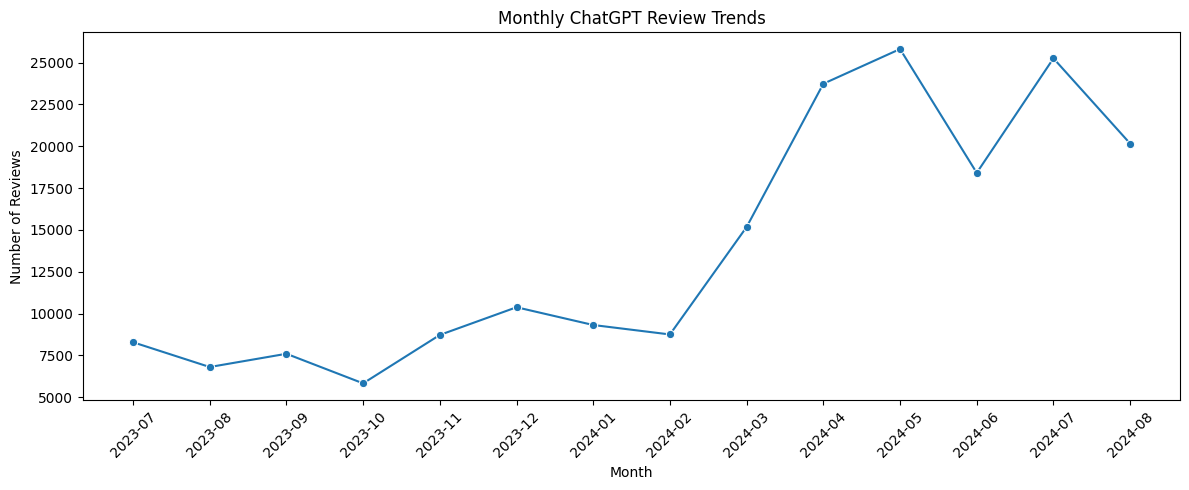

In [8]:

# Extract the month and year from each review date
df_clean["review_month"] = (
    df_clean["review_date"].dt.to_period("M").astype(str)
)

# Count reviews per month
monthly_reviews = (
    df_clean.groupby("review_month")
    .size()
    .sort_index()
)

print("Monthly review counts:")
print(monthly_reviews)

# Plot the monthly trend
plt.figure(figsize=(12, 5))

sns.lineplot(
    x=monthly_reviews.index,
    y=monthly_reviews.values,
    marker="o"
)

plt.title("Monthly ChatGPT Review Trends")
plt.xlabel("Month")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [9]:

!pip -q install textblob


In [10]:

from textblob import TextBlob

# Test the sentiment analyzer on sample reviews
sample_reviews = [
    "ChatGPT is amazing and very helpful.",
    "The app is terrible and frustrating.",
    "The application is okay."
]

for review in sample_reviews:
    sentiment = TextBlob(review).sentiment

    print("Review:", review)
    print("Polarity:", round(sentiment.polarity, 3))
    print("Subjectivity:", round(sentiment.subjectivity, 3))
    print("-" * 40)


Review: ChatGPT is amazing and very helpful.
Polarity: 0.4
Subjectivity: 0.6
----------------------------------------
Review: The app is terrible and frustrating.
Polarity: -0.7
Subjectivity: 0.95
----------------------------------------
Review: The application is okay.
Polarity: 0.5
Subjectivity: 0.5
----------------------------------------


In [11]:

from textblob import TextBlob
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Work with the cleaned review text
df_text = df_text.copy()

# Calculate polarity and subjectivity
df_text["polarity"] = df_text["review"].apply(
    lambda text: TextBlob(text).sentiment.polarity
)

df_text["subjectivity"] = df_text["review"].apply(
    lambda text: TextBlob(text).sentiment.subjectivity
)

# Classify each review by polarity
def classify_sentiment(polarity):
    if polarity > 0:
        return "Positive"
    elif polarity < 0:
        return "Negative"
    else:
        return "Neutral"

df_text["sentiment"] = df_text["polarity"].apply(
    classify_sentiment
)

# Display sample results
display(
    df_text[
        ["review", "ratings", "polarity",
         "subjectivity", "sentiment"]
    ].head(10)
)

print("\nSentiment analysis completed.")
print("Total reviews analyzed:", len(df_text))


,review,ratings,polarity,subjectivity,sentiment
0,good,5,0.7000,0.600000,Positive
1,good,5,0.7000,0.600000,Positive
2,nice app,5,0.6000,1.000000,Positive
3,"nice, ig",5,0.6000,1.000000,Positive
4,"this is a great app, the bot is so accurate to...",5,0.4125,0.542949,Positive
5,so nice app,5,0.6000,1.000000,Positive
6,"just love this app, or guy",4,0.5000,0.600000,Positive
7,great app,1,0.8000,0.750000,Positive
8,Very impressive,5,1.0000,1.000000,Positive
9,helps with coding a lot this ai is great for e...,5,0.8000,0.750000,Positive



Sentiment analysis completed.
Total reviews analyzed: 194210


Sentiment counts:
sentiment
Positive    148219
Neutral      37922
Negative      8069
Name: count, dtype: int64

Sentiment percentages:
sentiment
Positive    76.32
Neutral     19.53
Negative     4.15
Name: proportion, dtype: float64


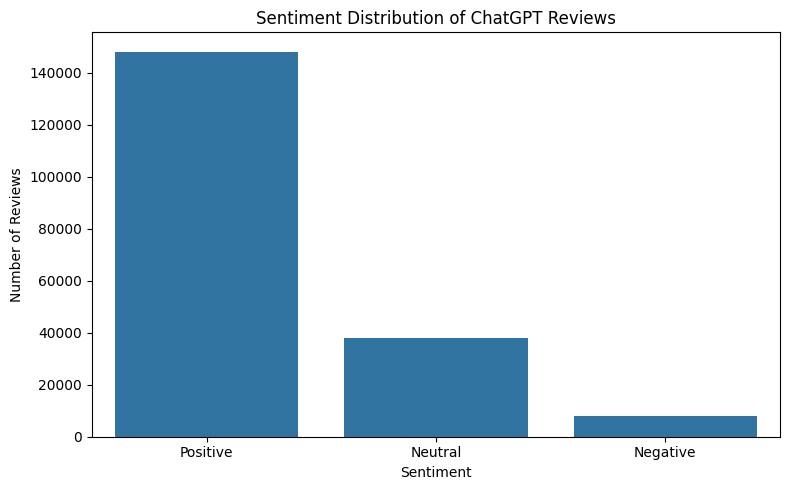

In [12]:

# Count and calculate percentages for each sentiment
sentiment_counts = df_text["sentiment"].value_counts()

sentiment_percentages = (
    df_text["sentiment"].value_counts(normalize=True) * 100
)

print("Sentiment counts:")
print(sentiment_counts)

print("\nSentiment percentages:")
print(sentiment_percentages.round(2))

# Plot sentiment distribution
plt.figure(figsize=(8, 5))

sns.countplot(
    data=df_text,
    x="sentiment",
    order=["Positive", "Neutral", "Negative"]
)

plt.title("Sentiment Distribution of ChatGPT Reviews")
plt.xlabel("Sentiment")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()


Sentiment percentages within each rating:


sentiment,Negative,Neutral,Positive
ratings,,,
1,29.78,38.77,31.45
2,21.13,29.02,49.85
3,10.22,23.75,66.03
4,3.85,17.50,78.65
5,1.42,17.84,80.74


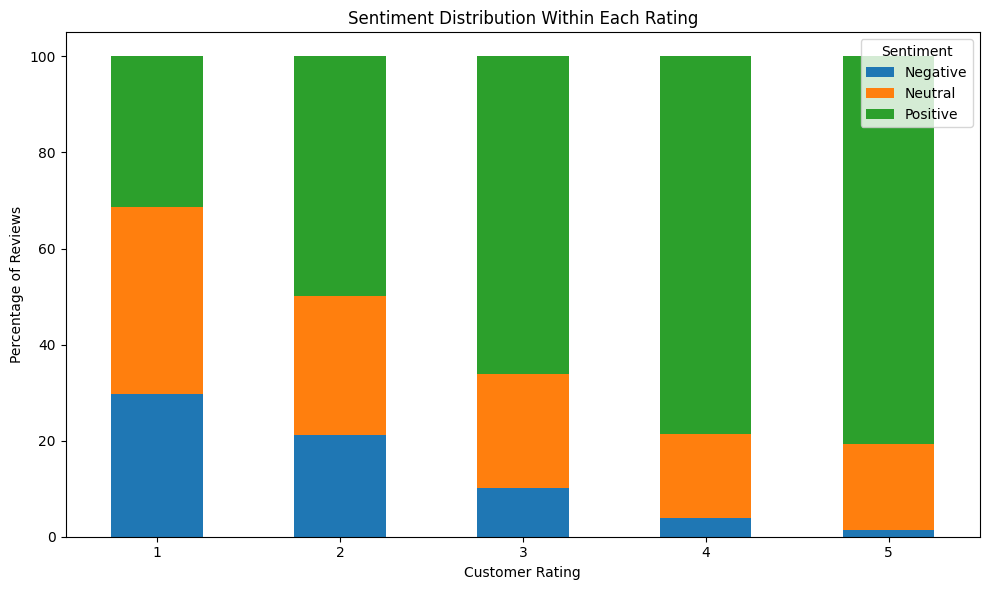

In [13]:

# Cross-tabulation of ratings and sentiment
rating_sentiment = pd.crosstab(
    df_text["ratings"],
    df_text["sentiment"],
    normalize="index"
) * 100

print("Sentiment percentages within each rating:")
display(rating_sentiment.round(2))

# Visualize the relationship
rating_sentiment.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 6)
)

plt.title("Sentiment Distribution Within Each Rating")
plt.xlabel("Customer Rating")
plt.ylabel("Percentage of Reviews")
plt.legend(title="Sentiment")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


In [14]:

!pip -q install wordcloud


Top 20 words in positive reviews:
good: 38637
best: 18087
nice: 13610
great: 11788
helpful: 9607
amazing: 8558
love: 8524
useful: 7474
excellent: 6068
awesome: 5014
chat: 4791
gpt: 4003
much: 3966
information: 3434
help: 3408
work: 3344
better: 3341
answers: 3040
answer: 3008
time: 2906


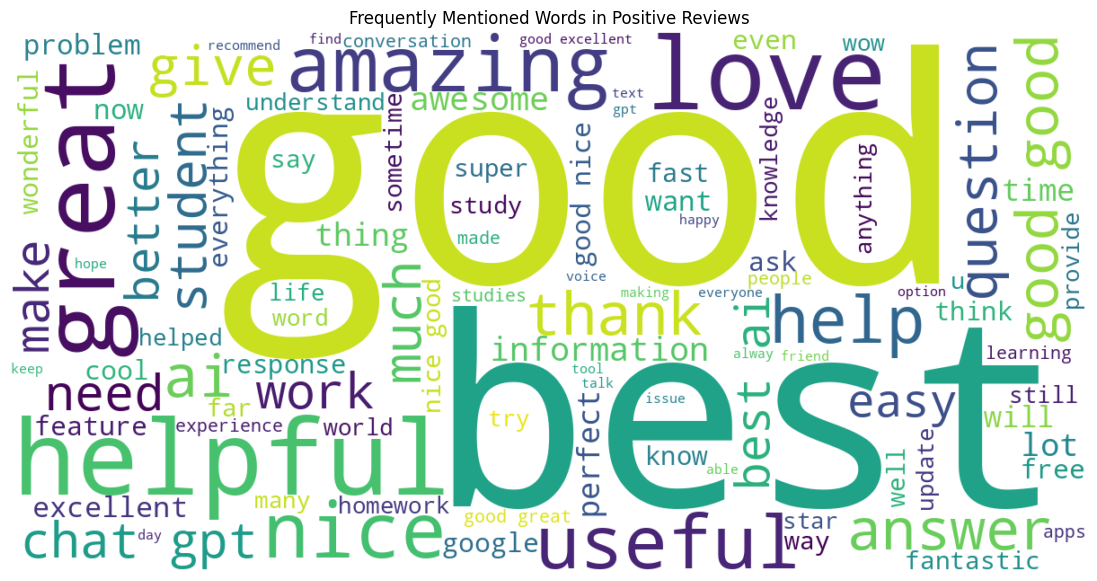

In [15]:

from collections import Counter
from wordcloud import WordCloud, STOPWORDS
import re
import matplotlib.pyplot as plt

# Select reviews classified as positive
positive_reviews = df_text.loc[
    df_text["sentiment"] == "Positive", "review"
]

# Combine the review text
positive_text = " ".join(positive_reviews.astype(str)).lower()

# Extract words, excluding common English words
stop_words = set(STOPWORDS)

# Add generic terms that may not be informative
stop_words.update([
    "chatgpt", "app", "application", "use", "using",
    "used", "really", "just", "one", "get", "like"
])

words = re.findall(r"\b[a-zA-Z]{3,}\b", positive_text)

filtered_words = [
    word for word in words if word not in stop_words
]

# Count the most frequent words
positive_word_counts = Counter(filtered_words)

print("Top 20 words in positive reviews:")
for word, count in positive_word_counts.most_common(20):
    print(f"{word}: {count}")

# Create a word cloud
wordcloud = WordCloud(
    width=1200,
    height=600,
    background_color="white",
    stopwords=stop_words,
    max_words=100
).generate(positive_text)

plt.figure(figsize=(14, 7))
plt.imshow(wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Frequently Mentioned Words in Positive Reviews")
plt.show()


Top 20 words in negative reviews:
wrong: 857
bad: 852
time: 615
answer: 567
don: 466
please: 452
information: 436
answers: 409
give: 405
doesn: 401
good: 397
now: 383
will: 371
worst: 359
work: 349
voice: 344
sometimes: 341
useless: 316
error: 304
questions: 303


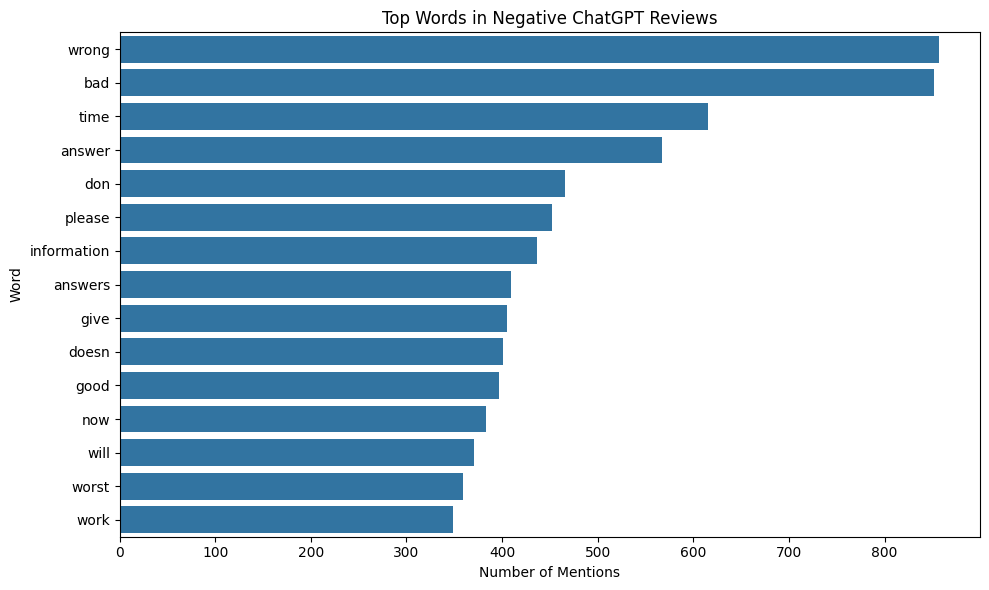

In [16]:

# Select reviews classified as negative
negative_reviews = df_text.loc[
    df_text["sentiment"] == "Negative", "review"
]

# Combine text
negative_text = " ".join(
    negative_reviews.astype(str)
).lower()

# Extend stop words to remove generic terms
negative_stop_words = set(STOPWORDS)

negative_stop_words.update([
    "chatgpt", "chat", "gpt", "app", "application",
    "use", "using", "used", "really", "just",
    "one", "get", "like", "much", "even"
])

# Extract words
negative_words = re.findall(
    r"\b[a-zA-Z]{3,}\b",
    negative_text
)

filtered_negative_words = [
    word for word in negative_words
    if word not in negative_stop_words
]

# Count word frequencies
negative_word_counts = Counter(filtered_negative_words)

print("Top 20 words in negative reviews:")

for word, count in negative_word_counts.most_common(20):
    print(f"{word}: {count}")

# Visualize the top 15 words
top_negative = negative_word_counts.most_common(15)

if top_negative:
    words, counts = zip(*top_negative)

    plt.figure(figsize=(10, 6))
    sns.barplot(x=list(counts), y=list(words))

    plt.title("Top Words in Negative ChatGPT Reviews")
    plt.xlabel("Number of Mentions")
    plt.ylabel("Word")
    plt.tight_layout()
    plt.show()
else:
    print("No negative words found.")


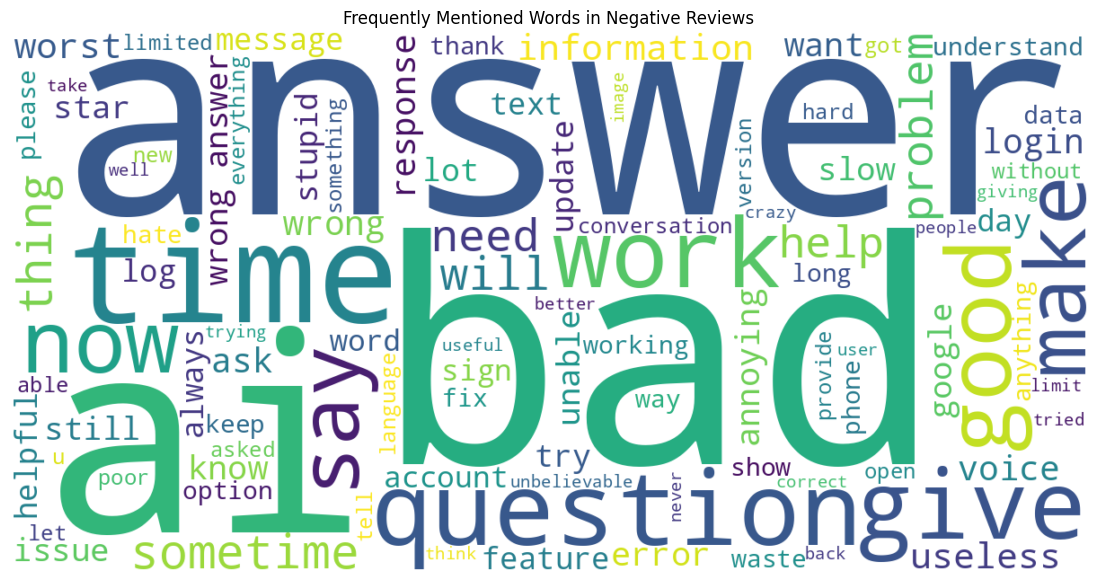

In [17]:

if negative_text.strip():
    negative_wordcloud = WordCloud(
        width=1200,
        height=600,
        background_color="white",
        stopwords=negative_stop_words,
        max_words=100
    ).generate(negative_text)

    plt.figure(figsize=(14, 7))
    plt.imshow(negative_wordcloud, interpolation="bilinear")
    plt.axis("off")
    plt.title("Frequently Mentioned Words in Negative Reviews")
    plt.show()
else:
    print("No negative reviews available for the word cloud.")


In [18]:

print("Total negative reviews:", len(negative_reviews))

print("\nTop 20 words in negative reviews:")
for word, count in negative_word_counts.most_common(20):
    print(f"{word}: {count}")


Total negative reviews: 8069

Top 20 words in negative reviews:
wrong: 857
bad: 852
time: 615
answer: 567
don: 466
please: 452
information: 436
answers: 409
give: 405
doesn: 401
good: 397
now: 383
will: 371
worst: 359
work: 349
voice: 344
sometimes: 341
useless: 316
error: 304
questions: 303


In [19]:

# Select negative reviews with 1- or 2-star ratings
critical_reviews = df_text[
    (df_text["sentiment"] == "Negative") &
    (df_text["ratings"].isin([1, 2]))
].copy()

print("Critical reviews available:", len(critical_reviews))

# Display 15 examples for manual inspection
display(
    critical_reviews[
        ["review", "ratings", "polarity"]
    ].head(15)
)


Critical reviews available: 4270


,review,ratings,polarity
119,not good,1,-0.350000
134,Too expensive,1,-0.500000
176,"Correct answer Accuracy 10 %,always provide wr...",1,-0.500000
222,"I get a ""something went wrong"" error so I can'...",1,-0.500000
262,So so bad not working on camera,1,-0.700000
303,This is not nice app I hate it 😡,1,-0.550000
313,chat gpt is helpful sometimes but there's some...,1,-0.450000
378,I failed my math homework :/,1,-0.375000
423,Log in to save chats. Except the one you've be...,1,-0.200000
462,"ChatGPT can't help my friend Jano loss weight,...",1,-0.166667


In [20]:

# Summary statistics for sentiment
print("Average polarity:",
      round(df_text["polarity"].mean(), 4))

print("Average subjectivity:",
      round(df_text["subjectivity"].mean(), 4))

print("\nAverage polarity by rating:")
display(
    df_text.groupby("ratings")["polarity"]
    .mean()
    .round(4)
)

print("\nAverage subjectivity by rating:")
display(
    df_text.groupby("ratings")["subjectivity"]
    .mean()
    .round(4)
)


Average polarity: 0.4469
Average subjectivity: 0.5167

Average polarity by rating:


,polarity
ratings,
1,0.0128
2,0.1579
3,0.3044
4,0.4249
5,0.4995



Average subjectivity by rating:


,subjectivity
ratings,
1,0.3807
2,0.4269
3,0.4662
4,0.5173
5,0.5323


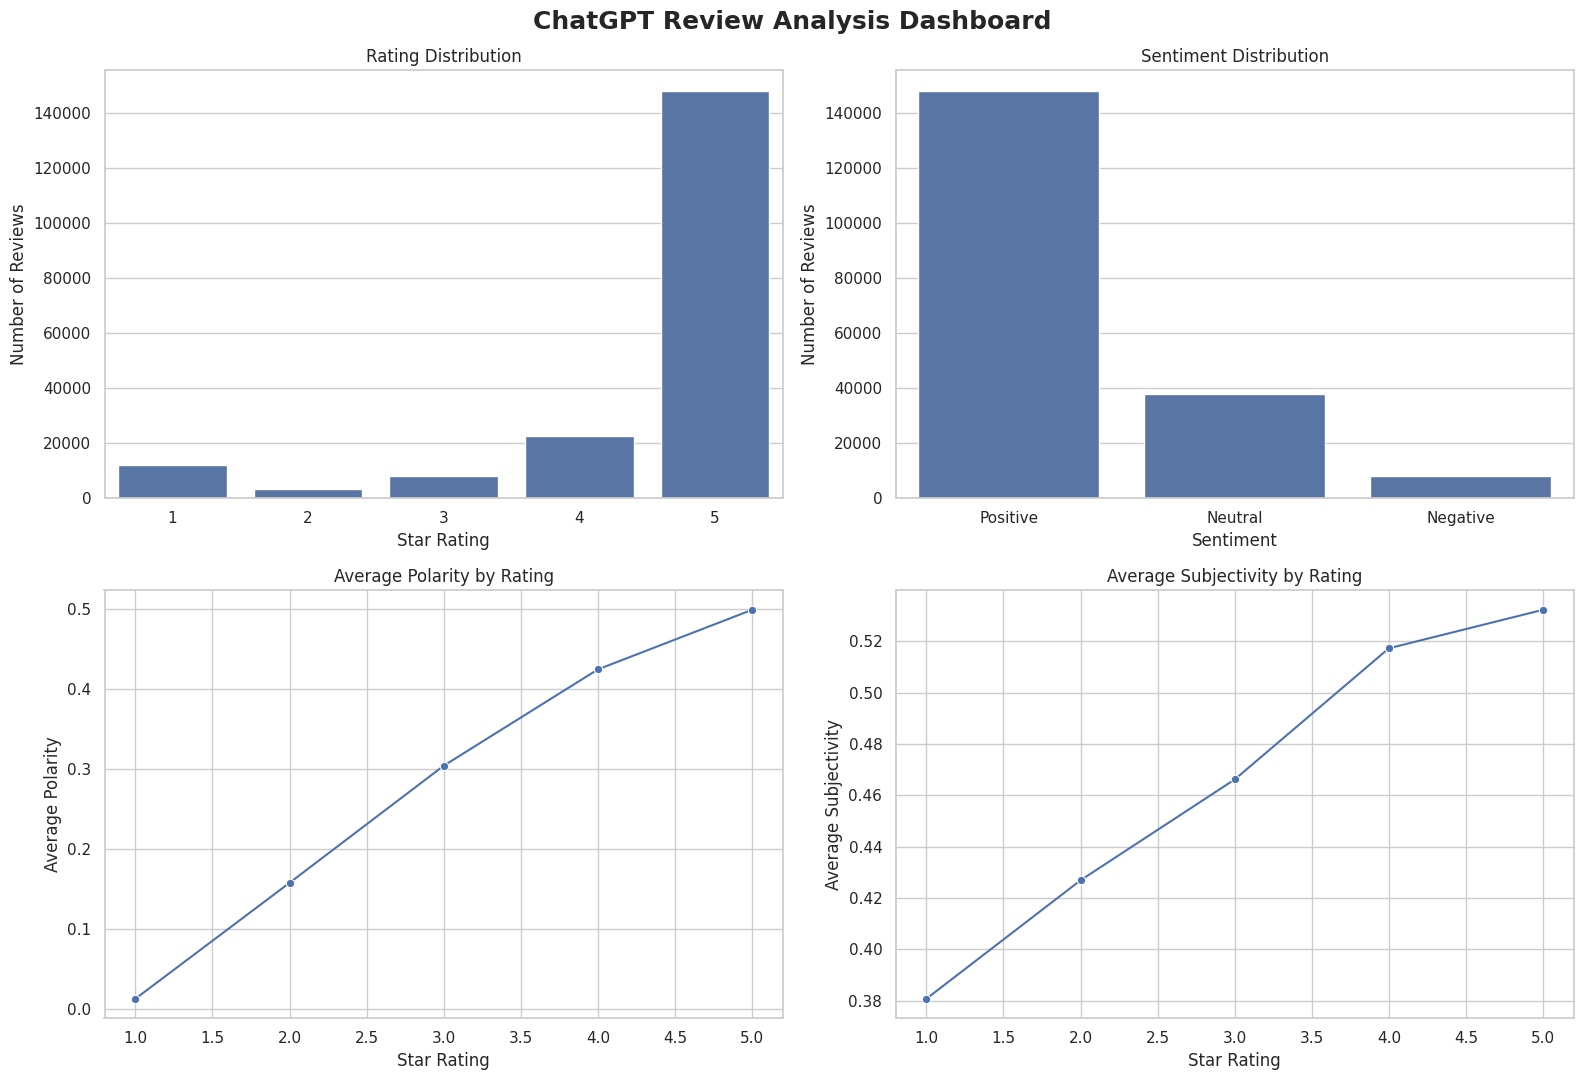

In [21]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

sns.set_theme(style="whitegrid")

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

# Chart 1: Rating distribution
rating_counts = df_clean["ratings"].value_counts().sort_index()

sns.barplot(
    x=rating_counts.index,
    y=rating_counts.values,
    ax=axes[0, 0]
)
axes[0, 0].set_title("Rating Distribution")
axes[0, 0].set_xlabel("Star Rating")
axes[0, 0].set_ylabel("Number of Reviews")

# Chart 2: Sentiment distribution
sentiment_order = ["Positive", "Neutral", "Negative"]

sns.countplot(
    data=df_text,
    x="sentiment",
    order=sentiment_order,
    ax=axes[0, 1]
)
axes[0, 1].set_title("Sentiment Distribution")
axes[0, 1].set_xlabel("Sentiment")
axes[0, 1].set_ylabel("Number of Reviews")

# Chart 3: Average polarity by rating
mean_polarity = df_text.groupby("ratings")["polarity"].mean()

sns.lineplot(
    x=mean_polarity.index,
    y=mean_polarity.values,
    marker="o",
    ax=axes[1, 0]
)
axes[1, 0].set_title("Average Polarity by Rating")
axes[1, 0].set_xlabel("Star Rating")
axes[1, 0].set_ylabel("Average Polarity")

# Chart 4: Average subjectivity by rating
mean_subjectivity = (
    df_text.groupby("ratings")["subjectivity"].mean()
)

sns.lineplot(
    x=mean_subjectivity.index,
    y=mean_subjectivity.values,
    marker="o",
    ax=axes[1, 1]
)
axes[1, 1].set_title("Average Subjectivity by Rating")
axes[1, 1].set_xlabel("Star Rating")
axes[1, 1].set_ylabel("Average Subjectivity")

plt.suptitle(
    "ChatGPT Review Analysis Dashboard",
    fontsize=18,
    fontweight="bold"
)
plt.tight_layout()
plt.show()


In [22]:

# FINAL PROJECT SUMMARY

total_reviews = len(df_clean)
analyzed_reviews = len(df_text)

five_star_pct = (
    (df_clean["ratings"] == 5).mean() * 100
)

positive_pct = (
    (df_text["sentiment"] == "Positive").mean() * 100
)

negative_pct = (
    (df_text["sentiment"] == "Negative").mean() * 100
)

neutral_pct = (
    (df_text["sentiment"] == "Neutral").mean() * 100
)

print("=" * 45)
print("CHATGPT REVIEW ANALYSIS - FINAL SUMMARY")
print("=" * 45)

print(f"Reviews after duplicate removal: {total_reviews:,}")
print(f"Reviews analyzed for sentiment: {analyzed_reviews:,}")
print(f"Five-star ratings: {five_star_pct:.2f}%")
print(f"Positive sentiment: {positive_pct:.2f}%")
print(f"Neutral sentiment: {neutral_pct:.2f}%")
print(f"Negative sentiment: {negative_pct:.2f}%")
print(f"Average polarity: {df_text['polarity'].mean():.4f}")
print(f"Average subjectivity: {df_text['subjectivity'].mean():.4f}")

print("=" * 45)


CHATGPT REVIEW ANALYSIS - FINAL SUMMARY
Reviews after duplicate removal: 194,216
Reviews analyzed for sentiment: 194,210
Five-star ratings: 76.34%
Positive sentiment: 76.32%
Neutral sentiment: 19.53%
Negative sentiment: 4.15%
Average polarity: 0.4469
Average subjectivity: 0.5167


# Conclusion — ChatGPT Review Analysis

This project analyzed customer reviews of ChatGPT to understand user sentiment, identify recurring themes in customer feedback, and explore the relationship between written reviews and numerical ratings.

The original dataset contained 196,727 records and four columns: review ID, review text, rating, and review date. During preprocessing, 2,511 exact duplicate rows were removed, leaving 194,216 records. Six records with missing review text were excluded from text-based sentiment analysis, resulting in 194,210 reviews for analysis.

Exploratory data analysis revealed that 76.34% of the remaining records had a five-star rating, indicating that high ratings were prevalent in the dataset. Monthly review trends also showed variations in review activity over the observed period.

TextBlob was used to calculate sentiment polarity and subjectivity. The analysis classified 76.32% of reviews as positive, 19.53% as neutral, and 4.15% as negative. The average polarity was 0.4469, while average subjectivity was 0.5167, indicating a generally positive language tendency and a moderate degree of opinion-oriented language.

Keyword extraction identified positive terms such as “good,” “helpful,” “useful,” and “excellent.” Negative-review keywords included “wrong,” “bad,” “error,” and “useless.” These terms suggest that usefulness, answer quality, and reliability are important areas for further investigation.

The comparison between numerical ratings and textual sentiment demonstrated that the two measures do not always align. This highlights the value of combining structured rating data with natural language processing to obtain a broader understanding of customer feedback.

Overall, the project demonstrates how data preprocessing, exploratory analysis, sentiment scoring, keyword extraction, and visualization can be combined to analyze large volumes of customer reviews. Future work could use a context-aware sentiment model, validate classifications against manually labeled reviews, and apply topic modeling to identify specific product strengths and recurring user complaints.

The findings should be interpreted in light of the limitations of lexicon-based sentiment analysis. TextBlob may not accurately identify sarcasm, mixed sentiment, or context-dependent meanings. Therefore, the results represent automated estimates rather than definitive measures of customer satisfaction.